# 2. Train the Random Forest Classifier

Reads `data_processed/features.csv` (produced by notebook 1) and trains a
`RandomForestClassifier` to distinguish `human` vs `injected` typing.

**Key design choice — the train/test split is grouped, not random.**
Windows within a session overlap (window=20, step=5), so consecutive windows share most of
their keystrokes. A random row-level split would put near-duplicate windows on both sides
and give an inflated, meaningless accuracy.

For `human` rows we group by `subject_id` (not `session_id`): a person's multiple capture
sessions must all land on the same side of the split, otherwise the model can partly learn
that specific person's typing rhythm instead of generalizing to unseen humans. For `injected`
rows there is only one physical source (`subject_id == "inj"` for every session), so grouping
by subject there would put 100% of injected data on one side — instead we group those by
`session_id`, same as before, which still prevents overlapping-window leakage.


## Config

In [12]:
FEATURES_PATH = "../data/processed/features.csv" 
MODEL_DIR = "../model"
OUTPUTS_DIR = "../outputs"
TEST_SIZE = 0.25
SEED = 42

import os
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)


## Imports

In [13]:
import json

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit, cross_val_score, StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

%matplotlib inline


## Load features

Metadata columns (`source_file`, `label`, `subject_id`, `session_id`, `payload_variant`,
`window_start_seq`) are excluded from the model input — everything else in the CSV is
treated as a numeric feature automatically, so this stays in sync if you add more features
in notebook 1 later without touching this code.

NaNs (e.g. `cv_dwell` when a window has fewer than 2 valid dwell samples) are filled with a
sentinel value (-999) far outside the observed range, rather than the mean — the fact that a
stat *couldn't* be computed is itself a signal, and mean-imputing would smear it away.

In [14]:
META_COLS = ["source_file", "label", "subject_id", "session_id",
             "payload_variant", "window_start_seq"]
SENTINEL = -999

df = pd.read_csv(FEATURES_PATH)
feature_cols = [c for c in df.columns if c not in META_COLS]

X = df[feature_cols].fillna(SENTINEL)
y = (df["label"] == "injected").astype(int)   # 1 = injected, 0 = human

# Subject-independent for human data (avoids learning one person's rhythm),
# session-independent for injected data (only one physical device/subject exists).
groups = pd.Series(
    np.where(df["label"] == "human", df["subject_id"], df["session_id"]),
    index=df.index,
)

print(f"{len(df)} windows, {len(feature_cols)} features, {pd.Series(groups).nunique()} split-groups")
print(df["label"].value_counts())
X.head()


13046 windows, 12 features, 123 split-groups
label
injected    8150
human       4896
Name: count, dtype: int64


,mean_dwell_ms,std_dwell_ms,cv_dwell,n_dwell_outliers_excluded,mean_flight_ms,std_flight_ms,cv_flight,n_pauses_excluded,autorepeat_ratio,backspace_ratio,events_per_sec,n_devices_in_window
0,109.971985,23.494044,0.213637,0,201.515584,180.326140,0.894850,0,0.0,0.0,3.368770,1
1,111.532505,24.103884,0.216115,0,199.014470,190.992680,0.959692,0,0.0,0.0,3.524026,1
2,111.477850,24.057649,0.215807,0,175.303155,191.584534,1.092876,0,0.0,0.0,3.694730,1
3,113.166520,24.909279,0.220112,0,147.881905,191.194618,1.292887,0,0.0,0.0,3.982943,1
4,119.366870,25.537300,0.213940,0,136.567280,190.461085,1.394632,0,0.0,0.0,4.105582,1


## Session-grouped train/test split

In [15]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

sessions_train = set(groups.iloc[train_idx])
sessions_test = set(groups.iloc[test_idx])
assert sessions_train.isdisjoint(sessions_test), "session leakage between train/test!"

print(f"Train: {len(X_train)} windows across {len(sessions_train)} sessions")
print(f"Test:  {len(X_test)} windows across {len(sessions_test)} sessions")


Train: 9517 windows across 92 sessions
Test:  3529 windows across 31 sessions


## Train the Random Forest

`class_weight="balanced"` compensates for the human/injected counts not being exactly
equal.

In [16]:
clf = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED,
)
clf.fit(X_train, y_train)
print("Trained.")


Trained.


## Sanity check: grouped 5-fold cross-validation on the training set

Same session-grouping logic applied to CV folds, so this doesn't leak either. A quick check
that the held-out test score (next cell) isn't a fluke of one particular split.

In [17]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(clf, X_train, y_train, groups=groups.iloc[train_idx],
                             cv=cv, scoring="f1", n_jobs=-1)
print(f"5-fold grouped CV F1: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")


5-fold grouped CV F1: 0.9930 +/- 0.0069


## Evaluate on the held-out test sessions

In [18]:
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

report = classification_report(y_test, y_pred, target_names=["human", "injected"])
print(report)

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix [rows=true, cols=pred] (human, injected):")
print(cm)

auc = roc_auc_score(y_test, y_proba)
print(f"\nROC AUC: {auc:.4f}")


              precision    recall  f1-score   support

       human       1.00      0.98      0.99      1437
    injected       0.99      1.00      0.99      2092

    accuracy                           0.99      3529
   macro avg       0.99      0.99      0.99      3529
weighted avg       0.99      0.99      0.99      3529

Confusion matrix [rows=true, cols=pred] (human, injected):
[[1411   26]
 [   3 2089]]

ROC AUC: 0.9999


## Session-level evaluation

In practice you wouldn't act on a single 25-keystroke window — you'd watch a live session
and decide based on all its windows. This takes a majority vote across each test session's
windows and checks accuracy at that level.

In [19]:
test_df = df.iloc[test_idx].copy()
test_df["y_true"] = y_test.values
test_df["y_pred"] = y_pred

session_level = test_df.groupby("session_id").agg(
    y_true=("y_true", "first"),
    pred_injected_rate=("y_pred", "mean"),
)
session_level["y_pred"] = (session_level["pred_injected_rate"] >= 0.5).astype(int)
session_acc = (session_level["y_true"] == session_level["y_pred"]).mean()

print(f"Session-level majority-vote accuracy: {session_acc:.4f} ({len(session_level)} test sessions)")

misclassified = session_level[session_level["y_true"] != session_level["y_pred"]]
if len(misclassified):
    print("\nMisclassified sessions:")
    display(misclassified)
else:
    print("No misclassified sessions.")


Session-level majority-vote accuracy: 1.0000 (37 test sessions)
No misclassified sessions.


## Feature importances — what is the model actually keying off?

mean_dwell_ms                2.829615e-01
std_dwell_ms                 2.250131e-01
events_per_sec               1.610987e-01
cv_dwell                     1.368010e-01
std_flight_ms                8.748920e-02
mean_flight_ms               6.383575e-02
cv_flight                    2.468834e-02
backspace_ratio              1.224962e-02
n_pauses_excluded            5.744955e-03
autorepeat_ratio             1.175310e-04
n_dwell_outliers_excluded    2.600628e-07
n_devices_in_window          0.000000e+00
dtype: float64


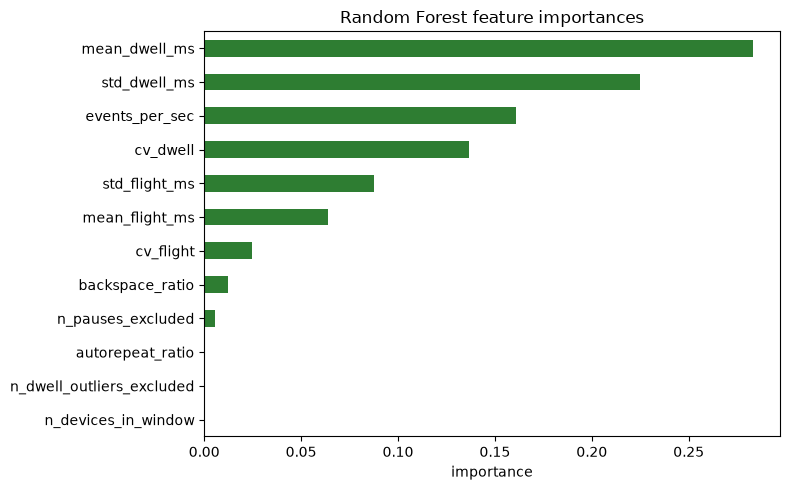

In [20]:
importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

fig, ax = plt.subplots(figsize=(8, 5))
importances.sort_values().plot.barh(ax=ax, color="#2e7d32")
ax.set_title("Random Forest feature importances")
ax.set_xlabel("importance")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "feature_importances.png"), dpi=130)
plt.show()


## ROC curve

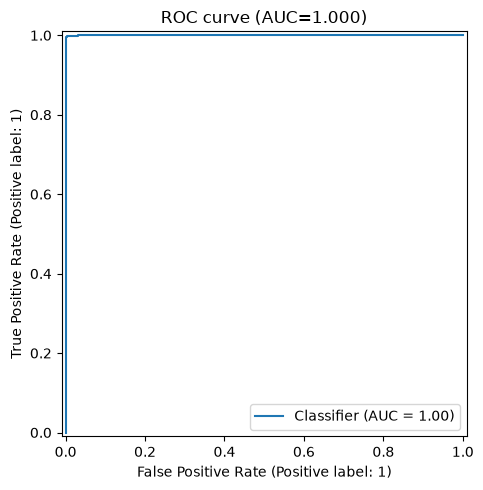

In [21]:
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax)
ax.set_title(f"ROC curve (AUC={auc:.3f})")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "roc_curve.png"), dpi=130)
plt.show()


## Save the model

Saves the trained classifier plus a metadata file (`model_meta.json`) recording the exact
feature column order, the NaN sentinel value, and the window size/step used — everything
`03_predict.ipynb` needs to reproduce features consistently on new data.

In [22]:
model_path = os.path.join(MODEL_DIR, "rf_model.joblib")
joblib.dump(clf, model_path)

meta = {
    "feature_columns": feature_cols,
    "sentinel_fill_value": SENTINEL,
    "label_mapping": {"0": "human", "1": "injected"},
    "window_size": 25,   # must match WINDOW used in notebook 1
    "window_step": 5,    # must match STEP used in notebook 1
    "test_auc": auc,
    "test_session_accuracy": session_acc,
}
with open(os.path.join(MODEL_DIR, "model_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)

with open(os.path.join(OUTPUTS_DIR, "classification_report.txt"), "w") as f:
    f.write(report)
    f.write(f"\nConfusion matrix [rows=true, cols=pred] (human, injected):\n{cm}\n")
    f.write(f"\nROC AUC: {auc:.4f}\n")
    f.write(f"Session-level majority-vote accuracy: {session_acc:.4f}\n")

print(f"Saved model -> {model_path}")
print(f"Saved metadata -> {MODEL_DIR}/model_meta.json")


Saved model -> ../model\rf_model.joblib
Saved metadata -> ../model/model_meta.json


---
**Next:** open `03_predict.ipynb` to classify new raw keystroke logs with this model.